In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Цель работы** — построить и сравнить модели машинного обучения для выявления мошеннических транзакций на синтетических данных с выраженным дисбалансом классов.

Для этого было выполнено:
1. первичная проверка,
2. EDA,
3. feature engineering,
4. временное разбиение выборки,
5. обучение нескольких моделей,
6. оценка,
7. визуализация

Данные взяты из открытого источника: https://www.kaggle.com/datasets/dermisfit/fraud-transactions-dataset/data

In [2]:
import numpy as np
import pandas as pd

In [3]:
import pandas as pd

!find /content/drive/MyDrive -name "fraudTest.csv" 2>/dev/null

/content/drive/MyDrive/fraudTest.csv


In [4]:
# Загружаю данные:
df = pd.read_csv('/content/drive/MyDrive/fraudTest.csv')

#EDA

In [5]:
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,...,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0
1,1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,...,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0
2,2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,...,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0
3,3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,...,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0
4,4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,...,44.2529,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0


In [6]:
df.shape

(555719, 23)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 555719 entries, 0 to 555718
Data columns (total 23 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Unnamed: 0             555719 non-null  int64  
 1   trans_date_trans_time  555719 non-null  object 
 2   cc_num                 555719 non-null  int64  
 3   merchant               555719 non-null  object 
 4   category               555719 non-null  object 
 5   amt                    555719 non-null  float64
 6   first                  555719 non-null  object 
 7   last                   555719 non-null  object 
 8   gender                 555719 non-null  object 
 9   street                 555719 non-null  object 
 10  city                   555719 non-null  object 
 11  state                  555719 non-null  object 
 12  zip                    555719 non-null  int64  
 13  lat                    555719 non-null  float64
 14  long                   555719 non-nu

In [8]:
df.describe()
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,555719.0,NaN,NaN,NaN,277859.0,160422.401459,0.0,138929.5,277859.0,416788.5,555718.0
trans_date_trans_time,555719,544760,2020-12-17 20:36:39,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cc_num,555719.0,NaN,NaN,NaN,417838695528764096.0,1309836622980698624.0,60416207185.0,180042946491150.0,3521417320836166.0,4635330563105903.0,4992346398065154048.0
merchant,555719,693,fraud_Kilback LLC,1859,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,555719,14,gas_transport,56370,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amt,555719.0,NaN,NaN,NaN,69.39281,156.745941,1.0,9.63,47.29,83.01,22768.11
first,555719,341,Christopher,11443,NaN,NaN,NaN,NaN,NaN,NaN,NaN
last,555719,471,Smith,12146,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,555719,2,F,304886,NaN,NaN,NaN,NaN,NaN,NaN,NaN
street,555719,924,444 Robert Mews,1474,NaN,NaN,NaN,NaN,NaN,NaN,NaN


555 719 строк, 23 столбца,
пропуски отсутствуют,

целевая переменная флаг фрода (is_fraud) — бинарная, с низким средним значением 0.00386, то есть в лданном датасете наблюдается стльный дисбаланс.  
сумма (amt) - среднее 69.4, максильмальное значение 22768.11, есть выбросы
В данных нет пустых строк, следовательно, нет шага с заменой пустых значений.

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
# Баланс классов
target_stats = df["is_fraud"].value_counts()
target_stats

,count
is_fraud,
0,553574
1,2145


In [11]:
# Статистики по сумме транзакции для легитимных и фрод
df.groupby("is_fraud")["amt"].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,553574.0,67.614408,152.471931,1.00,9.60,47.15,82.62,22768.11
1,2145.0,528.356494,392.747594,1.78,214.51,371.94,907.77,1320.92


1. легитимные операции: среднее 67.6, максимальное значение 22768.
2. мошеннические: среднее 528.4, максимальное значение 1320.92

мошеннические операции в среднем в 7–8 раз крупнее по сумме.

Визуализация

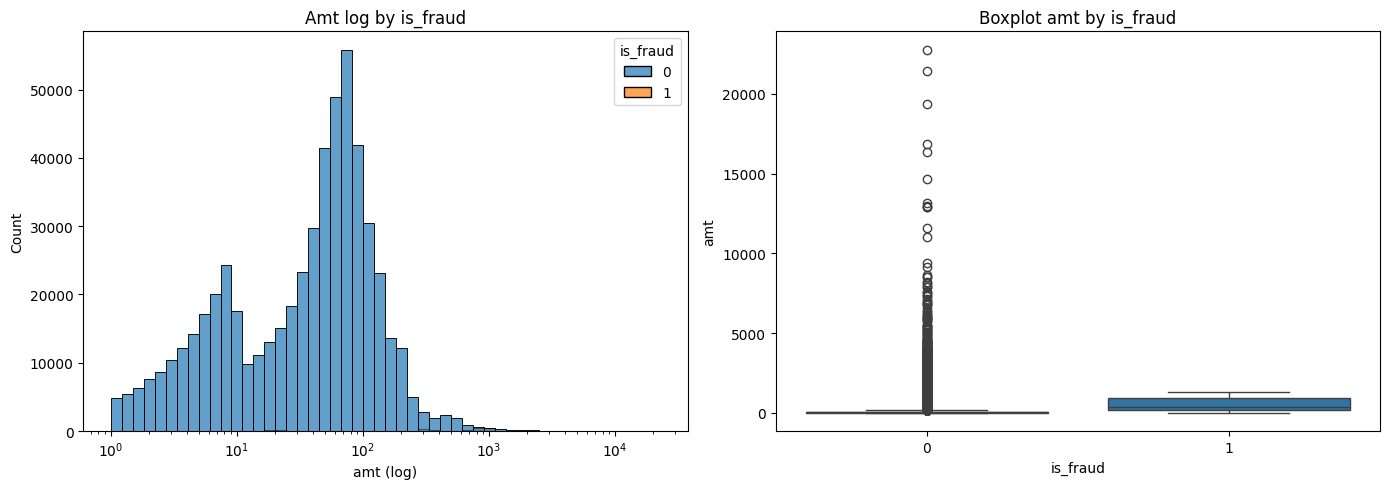

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 5))

# 1. Гистограмма суммы (логарифм, чтобы было нагляднее из-за выбросов)
plt.subplot(1, 2, 1)
sns.histplot(
    data=df,
    x="amt",
    hue="is_fraud",
    stat="count",
    bins=50,
    log_scale=True,
    alpha=0.7
)
plt.title("Amt log by is_fraud")
plt.xlabel("amt (log)")

# 2. Boxplot по сумме для двух классов
plt.subplot(1, 2, 2)
sns.boxplot(
    data=df,
    x="is_fraud",
    y="amt",
    showfliers=True
)
plt.title("Boxplot amt by is_fraud")
plt.ylabel("amt")

plt.tight_layout()
plt.show()

По графикам видно, что сумма перекрывается

Для is_fraud = 0:
очень большие выбросы вверх, вероятно, отражает легитимные крупные покупкки. То есть отдельные выбросы не являются признаком фрода.

Для is_fraud = 1:
Бокс уже, то есть для фрод операции характерны средние и крупные суммы.

Вывод по графикам:
Разброс и выбросы сильнее у легитимных операций, фрод операции в более узком, но высоком диапазоне сумм.

Вывод по сумме (amt):
Оставляю amt как логарифмированный признак и попробую добавить несколько бинарных.

#Feature engineering

In [13]:
# Удаляю ненужные признаки (индексы, id транзакций, номера карт)
df = df.drop(columns=[
    "Unnamed: 0",
    "trans_num",
    "cc_num",
    "first",
    "last",
    "street"
])

In [14]:
# Дата и время
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
df["hour"] = df["trans_date_trans_time"].dt.hour
df["day"] = df["trans_date_trans_time"].dt.day
df["month"] = df["trans_date_trans_time"].dt.month
df["day_of_week"] = df["trans_date_trans_time"].dt.dayofweek
df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)

In [15]:
#Удаляю исходную дату
df = df.drop(columns=["trans_date_trans_time"])

In [16]:
#Возраст клиента
df["dob"] = pd.to_datetime(df["dob"])
df["age"] = (pd.Timestamp("2020-12-31") - df["dob"]).dt.days // 365

df = df.drop(columns=["dob"])

In [17]:
# Логарифм суммы (для выбросов)
df['log_amt'] = np.log1p(df['amt'])

In [18]:
# Бины для сумм
df['amt_bin'] = pd.cut(df['amt'], bins=[0, 50, 200, 500, np.inf], labels=[0,1,2,3]).astype(int)

In [19]:
# География
# Евклидово расстояние
df['euclid_distance'] = np.sqrt(
    (df['lat'] - df['merch_lat'])**2 +
    (df['long'] - df['merch_long'])**2
)

# Логарифм расстояния (для выбросов)
df['log_distance'] = np.log1p(df['euclid_distance'])
df[['euclid_distance', 'log_distance']].describe()

,euclid_distance,log_distance
count,555719.000000,555719.000000
mean,0.765514,0.554525
std,0.284730,0.170068
min,0.001429,0.001428
25%,0.564412,0.447510
50%,0.798192,0.586781
75%,0.976997,0.681579
max,1.412221,0.880548


In [20]:
geo_cols = ['euclid_distance', 'log_distance']
df[geo_cols + ['is_fraud']].corr()['is_fraud'].sort_values(ascending=False)

,is_fraud
is_fraud,1.000000
euclid_distance,0.000523
log_distance,0.000443


Создала новые признаки времени, возраста, суммы и географии. При этом старые идентификаторы удалила, чтобы не влияло на модель и не было утечек (trans_date_trans_time)

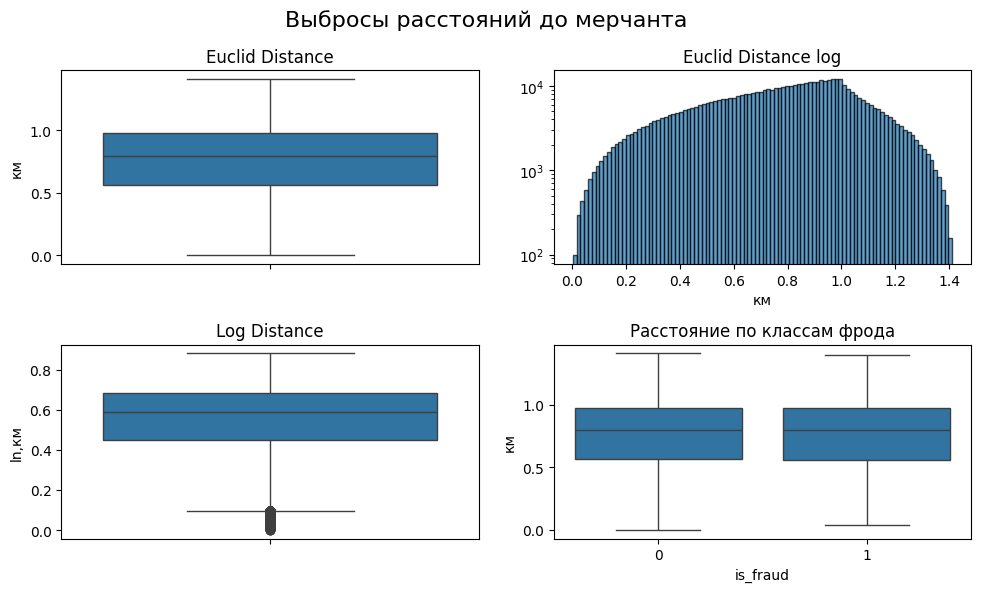

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
fig.suptitle('Выбросы расстояний до мерчанта', fontsize=16)

# Boxplot euclid_distance
sns.boxplot(data=df, y='euclid_distance', ax=axes[0,0])
axes[0,0].set_title('Euclid Distance')
axes[0,0].set_ylabel('км')

# Гистограмма euclid_distance (логарифм)
axes[0,1].hist(df['euclid_distance'], bins=100, alpha=0.7, edgecolor='black', log=True)
axes[0,1].set_title('Euclid Distance log')
axes[0,1].set_xlabel('км')

# Boxplot log_distance
sns.boxplot(data=df, y='log_distance', ax=axes[1,0])
axes[1,0].set_title('Log Distance')
axes[1,0].set_ylabel('ln,км')

# 4. Распределение по is_fraud
sns.boxplot(data=df, x='is_fraud', y='euclid_distance', ax=axes[1,1])
axes[1,1].set_title('Расстояние по классам фрода')
axes[1,1].set_ylabel('км')

plt.tight_layout()
plt.show()

по графикам:
1. euclid_distance имеет правостороннюю асимметрию, длинный хвост спррава.
2. log_distance делает распределение для моддели удобнее.
По классам is_fraud расстояния у фрода и легитимных операций перекрываются.

**Промежуточный итог:**
1. Удалены лишние признаки: Unnamed: 0, trans_num, cc_num, first, last, street;
2. Из даты извлечены hour, day, month, day_of_week, is_weekend;
3. Из dob получен age;
4. Для суммы создан log_amt, из-за асимметрии.
5. Для географии добавлены euclid_distance и log_distance и по графикам видно, что логарифмирование делает распределение более симметричным.

Далее оставляю признаки, которые не используют информацию из будущего.
Все преобразования, которые учатся на данных, делаю только на train.

In [23]:
# Сортирую данные по времени транзакции
df = df.sort_values('unix_time').reset_index(drop=True)

# Разбиваю на трейн / валидацию / тест по времени
split_1 = int(len(df) * 0.7)
split_2 = int(len(df) * 0.85)

train_df = df.iloc[:split_1].copy()
valid_df = df.iloc[split_1:split_2].copy()
test_df  = df.iloc[split_2:].copy()

print(train_df.shape, valid_df.shape, test_df.shape)

(389003, 25) (83358, 25) (83358, 25)


Выполнила временное разбиение данных на обучающую, валидационную и тестовую выборки. Сначала данные сортируются по unix_time, чтобы сохранить хронологический порядок транзакций, далее первые 70% наблюдений используются для обучения, следующие 15% для валидации, последние 15% для тестирования.

Такой подход использую, потому что при выполнении работы столкнулась с тем, что модель обучалась на прошлых данных и результаты получились завышенными.

In [24]:
# Удаляю лишние столбцы
# Сначала делала без юникстайм, в результате анализа выявлено, что данный признак также приводит модель к утечке данных, поэтому тоже удалила, ранее был нужен для хронологического разбиения
drop_cols = [
    'Unnamed: 0', 'cc_num', 'first', 'last', 'street',
    'trans_num', 'trans_date_trans_time', 'dob', 'unix_time'
]

df = df.drop(columns=[col for col in drop_cols if col in df.columns]).copy()

# Повторно делю уже очищенный df по времени
df = df.sort_values('unix_time').reset_index(drop=True) if 'unix_time' in df.columns else df.copy()

# Очищаю от лишних столбцов
for frame in [train_df, valid_df, test_df]:
    for col in drop_cols:
        if col in frame.columns:
            frame.drop(columns=[col], inplace=True)

y_train = train_df['is_fraud']
X_train = train_df.drop(columns=['is_fraud'])

y_valid = valid_df['is_fraud']
X_valid = valid_df.drop(columns=['is_fraud'])

y_test = test_df['is_fraud']
X_test = test_df.drop(columns=['is_fraud'])

print("Train:", X_train.shape, y_train.shape)
print("Valid:", X_valid.shape, y_valid.shape)
print("Test :", X_test.shape, y_test.shape)

Train: (389003, 23) (389003,)
Valid: (83358, 23) (83358,)
Test : (83358, 23) (83358,)


Сформировала признаки и целевую переменную для всех трёх выборок

1. Train (389003, 23) — обучающая выборка;
2. Valid (83358, 23) — валидация;
3. Test (83358, 23) — финальный тест.

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report, roc_curve, auc
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.neighbors import KNeighborsClassifier

In [26]:
# Определяю числовые и категориальные признакми
num_features = [
    'amt', 'hour', 'day', 'month', 'day_of_week', 'is_weekend',
    'age', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long',
    'euclid_distance', 'log_distance'
]

cat_features = ['merchant', 'category', 'gender', 'city', 'state', 'job']

num_features = [c for c in num_features if c in X_train.columns]
cat_features = [c for c in cat_features if c in X_train.columns]

print("num_features:", num_features)
print("cat_features:", cat_features)

num_features: ['amt', 'hour', 'day', 'month', 'day_of_week', 'is_weekend', 'age', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long', 'euclid_distance', 'log_distance']
cat_features: ['merchant', 'category', 'gender', 'city', 'state', 'job']


Вывела список числовых и категориальных признаков, которые далее будут подаваться в пайплайн

#Preprocessing

In [27]:
# Пайплайны
# Числовые признаки
"""
Создаю несколько пайплайнов для разных типов признаков, а затем объединяю их через ColumnTransformer
"""

"""
Заменяю пропуски медианой и масштабирую данные с помощью StandardScaler,
то есть привожу признаки к среднему 0 и стандартному отклонению 1.
"""

numeric_standard = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

"""
Вместо стандартизации использую минмакс.
Переводит значения в диапазон от 0 до 1

"""
numeric_minmax = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

"""
Для числовых признаков выполняется только заполнение пропусков,
а масштабирования нет
"""
numeric_noscale = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

#Категориальные признаки

"""
Сначала пропуски в категориальных столбцах заменяю самым частым значением (most_frequent), а потом применяю one hot.
OneHotEncoder превращает категории в набор бинарных столбцов. handle_unknown='ignore', чтобы модель не падала,
если в тестовой выборке встретится новая категория, которой не было на обучении
"""
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

"""
ColumnTransformer позволяет применить разные преобразования к разным колонкам.
К числовым признакам из num_features применяется numeric_standard, а к категориальным из cat_features categorical_transformer.
"""
preprocessor_standard = ColumnTransformer(
    transformers=[
        ('num', numeric_standard, num_features),
        ('cat', categorical_transformer, cat_features)
    ]
)

"""
Три варианта препроцессинга:
Три ColumnTransformer:
- preprocessor_standard  — числовые признаки стандартизируются.
- preprocessor_minmax — числовые признаки масштабируются в диапазон от 0 до 1.
- preprocessor_noscale — числовые признаки только заполняются по медиане.
- preprocessor_tree — мало отличается от preprocessor_noscale, применила, чтобы выбрать вариант под конкретную модель
"""
preprocessor_minmax = ColumnTransformer(
    transformers=[
        ('num', numeric_minmax, num_features),
        ('cat', categorical_transformer, cat_features)
    ]
)

preprocessor_noscale = ColumnTransformer(
    transformers=[
        ('num', numeric_noscale, num_features),
        ('cat', categorical_transformer, cat_features)
    ]
)

preprocessor_tree = ColumnTransformer(
    transformers=[
        ('num', numeric_noscale, num_features),
        ('cat', categorical_transformer, cat_features)
    ]
)

In [28]:
preprocessor_standard

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['amt', 'hour', 'day', 'month', 'day_of_week',
                                  'is_weekend', 'age', 'lat', 'long',
                                  'city_pop', 'merch_lat', 'merch_long',
                                  'euclid_distance', 'log_distance']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['merchant', 'category', 'gender', 'city',
                                  'state', 'job'])])

In [29]:
numeric_minmax

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', MinMaxScaler())])

In [30]:
preprocessor_tree

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['amt', 'hour', 'day', 'month', 'day_of_week',
                                  'is_weekend', 'age', 'lat', 'long',
                                  'city_pop', 'merch_lat', 'merch_long',
                                  'euclid_distance', 'log_distance']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['merchant', 'category', 'gender', 'city',
                                  'state', 'job'])])

Задаю три варианта обработки числовых признаков для логистической регрессии и единый вариант без масштабирования для деревьев и бустинга. Категориальные признаки кодирую через one hot внутри пайплайна

In [31]:
# Модели
models = {
    'LogReg_StandardScaler': Pipeline(steps=[
        ('preprocessor', preprocessor_standard),
        ('model', LogisticRegression(max_iter=5000, class_weight='balanced'))
    ]),
    'LogReg_MinMaxScaler': Pipeline(steps=[
        ('preprocessor', preprocessor_minmax),
        ('model', LogisticRegression(max_iter=5000, class_weight='balanced'))
    ]),
    'LogReg_NoScaling': Pipeline(steps=[
        ('preprocessor', preprocessor_noscale),
        ('model', LogisticRegression(max_iter=5000, class_weight='balanced'))
    ]),
    'RandomForest': Pipeline(steps=[
        ('preprocessor', preprocessor_tree),
        ('model', RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight='balanced',
            n_jobs=-1
        ))
    ]),
    'XGBoost': Pipeline(steps=[
        ('preprocessor', preprocessor_tree),
        ('model', XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=5,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric='logloss'
        ))
    ]),
    'LightGBM': Pipeline(steps=[
        ('preprocessor', preprocessor_tree),
        ('model', LGBMClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=-1,
            random_state=42,
            class_weight='balanced'
        ))
    ])
}

В регрессии решила попробовать и минмакс, и стандартскеллер, и без шкалирования переменных, чтобы выбрать лучший вариант + пробую моддели RF и бустинги на тех же данных.

*Для информации*: Ранее была попытка сделать и KNN, но для такого объема строк модель очень долго выполняла запрос + бустинг показывал результаты лучше, так что данную модель исключила из анализа и добавила логистическю регрессию, так как у меня работа с бинарным признаком фрод/не фрод.
+ В регрессии max_iter=5000 из-за полученной ранее ошибки

По коду:
**RF**
1. n_estimators=300 - 300 деревьев
2. random_state=42 - фиксирую случайность
3. class_weight='balanced' - учитываю влияние редкого класса (с учетом дисбаланса фрод/не фрод операций)
4. n_jobs=-1 - прочитала, что это позволяет ускорить обучение

**XGBoost** — градиентный бустинг по деревьям, который строит последовательность деревьев и каждый новый шаг пытается исправить ошибки предыдущих
1. n_estimators=300 — количество деревьев  
2. learning_rate=0.05 — шаг обучения.
3. max_depth=5 — максимальная глубина дерева. Влияет на переобучение.
4. subsample=0.8 — на каждой итерации используется 80% объектов. Снижает переобучение.
5. colsample_bytree=0.8 — на каждое дерево берётся 80% признаков. Также нижает переобучение.
6. random_state=42 — фиксирует случайность.
7. eval_metric='logloss' — метрика, по которой XGBoost оценивает качество на этапе обучения для бинарной классификации.

**LightGBM** - быстрее XGBoost, но качеством может быть хуже
1. n_estimators=300 — количество деревьев.
2. learning_rate=0.05 — шаг обучения.
3. max_depth=-1 — с учетом того, что в XGBoost я взяла 5, тут решила попробовать 1 для сравнения.
4. random_state=42 — фиксирует случайность.
5. class_weight='balanced' — дисбаланс классов, как в RF.




In [32]:
results = []

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_valid)
    y_proba = pipe.predict_proba(X_valid)[:, 1]

    results.append({
        'model': name,
        'precision': precision_score(y_valid, y_pred),
        'recall': recall_score(y_valid, y_pred),
        'f1': f1_score(y_valid, y_pred),
        'roc_auc': roc_auc_score(y_valid, y_proba),
        'pr_auc': average_precision_score(y_valid, y_proba)
    })

result_df = pd.DataFrame(results).sort_values('pr_auc', ascending=False)
print(result_df.to_string(index=False))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


[LightGBM] [Info] Number of positive: 1776, number of negative: 387227
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 1.795761 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6322
[LightGBM] [Info] Number of data points in the train set: 389003, number of used features: 2084
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


                model  precision   recall       f1  roc_auc   pr_auc
              XGBoost   0.959770 0.590106 0.730853 0.994184 0.829271
             LightGBM   0.457944 0.865724 0.599022 0.996137 0.813725
         RandomForest   0.984848 0.229682 0.372493 0.970244 0.771264
     LogReg_NoScaling   0.024664 0.759717 0.047778 0.888501 0.122799
LogReg_StandardScaler   0.009427 0.176678 0.017899 0.770141 0.011350
  LogReg_MinMaxScaler   0.005375 0.113074 0.010263 0.729935 0.009091


Выполнила сравнение моделей на тестовой выборке, которая не участвовала ни в обучении, ни в препроцессинге

In [35]:
result_df = pd.DataFrame(results).sort_values('pr_auc', ascending=False)

result_df['precision'] = result_df['precision'].round(4)
result_df['recall'] = result_df['recall'].round(4)
result_df['f1'] = result_df['f1'].round(4)
result_df['roc_auc'] = result_df['roc_auc'].round(4)
result_df['pr_auc'] = result_df['pr_auc'].round(4)

print(result_df.to_string(index=False))

                model  precision  recall     f1  roc_auc  pr_auc
              XGBoost     0.9598  0.5901 0.7309   0.9942  0.8293
             LightGBM     0.4579  0.8657 0.5990   0.9961  0.8137
         RandomForest     0.9848  0.2297 0.3725   0.9702  0.7713
     LogReg_NoScaling     0.0247  0.7597 0.0478   0.8885  0.1228
LogReg_StandardScaler     0.0094  0.1767 0.0179   0.7701  0.0113
  LogReg_MinMaxScaler     0.0054  0.1131 0.0103   0.7299  0.0091


По результатам лучшая модель XGBoost: у нее самый высокий PR-AUC = 0.8293, очень высокий ROC-AUC = 0.9942 + баланс между precision 0.9598 и recall 0.5901.

По всем моделям:
XGBoost — лучший вариант для задачи. Ловит мошеннические операции и при этом не теряет precision.

LightGBM — тоже сильная модель, у неё высокий recall = 0.8657 и ROC-AUC = 0.9961, но precision заметно ниже, значит она чаще даёт ложные сработки.

RandomForest — Самый высокий высокий precision 0.9848, но recall 0.2297, то есть пропускает много фродовых операций.

Logistic Regression во всех трёх вариантах дала низкие значения, особенно по PR-AUC.

###Анализ ошибок лучшей модели

In [42]:
# Лучшая модель + анализ ошибок
best_model_name = result_df.iloc[0]['model']
best_pipe = [pipe for name, pipe in models.items() if name == best_model_name][0]

best_pipe.fit(X_train, y_train)
y_pred_best = best_pipe.predict(X_test)
y_proba_best = best_pipe.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred_best)
tn, fp, fn, tp = cm.ravel()

error_df = pd.DataFrame({
    'metric': ['TN', 'FP', 'FN', 'TP', 'Total errors', 'Error rate'],
    'value': [tn, fp, fn, tp, fp + fn, (fp + fn) / len(y_test)]
})
print(error_df.to_string(index=False))

# Classification Report
print(classification_report(y_test, y_pred_best, target_names=['Не фрод', 'Фрод'], zero_division=0))

      metric        value
          TN 83262.000000
          FP    10.000000
          FN    31.000000
          TP    55.000000
Total errors    41.000000
  Error rate     0.000492
              precision    recall  f1-score   support

     Не фрод       1.00      1.00      1.00     83272
        Фрод       0.85      0.64      0.73        86

    accuracy                           1.00     83358
   macro avg       0.92      0.82      0.86     83358
weighted avg       1.00      1.00      1.00     83358



In [43]:
best_model_name

'XGBoost'

Матрица ошибок для XGBoost.  
Модель допустила всего 41 ошибку на всей тестовой выборке, почти не создаёт ложных рассчетов и при этом хорошо находит мошеннические операции.

1. TN - 83262 легитимные операции правильно распознаны как легитимные (0).
2. FP — 10 легитимных операций ошибочно помечены как фрод (1).
3. FN — 31 мошенническая операция пропущена моделью.
4. TP — 55 мошеннических операций найдены правильно.




In [45]:
print(classification_report(y_test, y_pred_best, digits=4, zero_division=0))

              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     83272
           1     0.8462    0.6395    0.7285        86

    accuracy                         0.9995     83358
   macro avg     0.9229    0.8197    0.8641     83358
weighted avg     0.9995    0.9995    0.9995     83358



**0:**

1. precision 0.9996 — почти все предсказанные легитимные операции легитимные.
2. recall 0.9999 — модель почти не расценивает легитимные операции как мошеннические.
3. f1-score 0.9998 — результат.
4. support 83272 — объектов данного класса было в тесте.

**1:**

1. precision 0.8462 — из всех операций, которые модель оценила мошенническими, 84.6% действительно мошеннические.
2. recall 0.6395 — модель находит около 64% всех мошеннических операций.
3. f1-score 0.7285 — результат.
5. support 86 — объектов данного класса было в тесте.

### Матрица ошибок

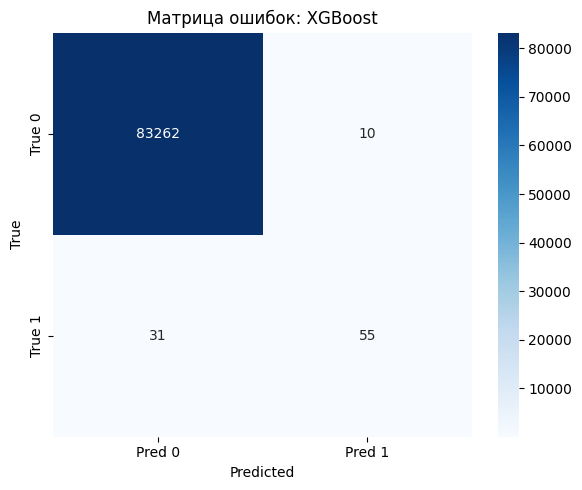

In [46]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Pred 0', 'Pred 1'],
    yticklabels=['True 0', 'True 1']
)
plt.title(f'Матрица ошибок: {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.tight_layout()
plt.show()

### ROC-AUC

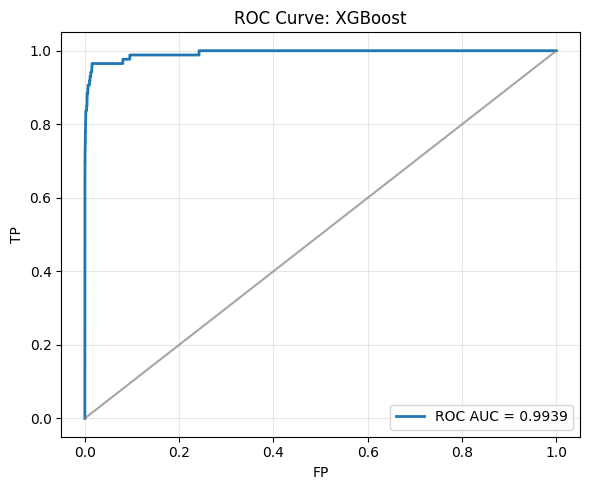

In [48]:
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(y_test, y_proba_best)
roc_value = roc_auc_score(y_test, y_proba_best)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC AUC = {roc_value:.4f}', linewidth=2)
plt.plot([0, 1], [0, 1], linestyle='-', color='gray', alpha=0.7)
plt.xlabel('FP')
plt.ylabel('TP')
plt.title(f'ROC Curve: {best_model_name}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()